# CycloneVision AI -- Unified Multi-Modal Pipeline
**SIH Problem Statement ID:** 26070 | **Organization:** MoES / IMD  
**Target Basin:** North Indian Ocean (Bay of Bengal & Arabian Sea)  

---
### Pipeline Overview:
1. **Data Ingestion & Dataset Splitting** (HDF5 Multi-Spectral Images, ERA5 NWP, IBTrACS Tracks)
2. **Model 1: Vortex Identification & Eye Localization** -- 3 simultaneous outputs
3. **Training** with 15 epochs + Early Stopping + LR Scheduling
4. **Full Test Evaluation** -- Accuracy, F1, Precision, Recall, BBox MAE, Dice Score
5. **Final Precision Dashboard** -- Clean summary of all model performance metrics

## Step 1: System Imports & Path Configuration

In [1]:
import os
import sys
import json
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, Subset

# Ensure project root is in sys.path
BASE_DIR = os.path.abspath(os.getcwd())
for sub in ["", "data_fusion", "data_preprocess", "numeric_data", "models", "actual_data_split"]:
    p = os.path.join(BASE_DIR, sub) if sub else BASE_DIR
    if p not in sys.path:
        sys.path.append(p)

from vortex_identification_model import get_device
device = get_device()

print(f"[+] Workspace Root   : {BASE_DIR}")
print(f"[+] PyTorch Version  : {torch.__version__}")
print(f"[+] Compute Device   : {str(device).upper()} (AMD Radeon GPU via DirectML)")


[+] Workspace Root   : c:\Users\HP\Desktop\cyclone
[+] PyTorch Version  : 2.4.1+cpu
[+] Compute Device   : PRIVATEUSEONE:0 (AMD Radeon GPU via DirectML)


## Step 2: Load Multi-Modal Dataset & Data Splits (Train / Val / Test)

In [ ]:
import os
import sys
import numpy as np
from torch.utils.data import DataLoader

BASE_DIR = os.path.abspath(os.getcwd())
for subdir in ["", "data_fusion", "data_preprocess", "numeric_data", "models", "actual_data_split"]:
    path = os.path.join(BASE_DIR, subdir) if subdir else BASE_DIR
    if path not in sys.path:
        sys.path.append(path)

from data_fusion.data_fusion_pipeline import CycloneVisionMultiModalDataset
from actual_data_split.split_manager import AugmentedSplitDataset

ANNOTATION_CSV = os.path.join(BASE_DIR, "cyclone_image", "image_annotations.csv")
if not os.path.isfile(ANNOTATION_CSV):
    raise FileNotFoundError(
        "Model 1 training needs cyclone_image/image_annotations.csv with verified image_index, "
        "vortex_presence, split, storm_id, eye boxes, and eyewall masks."
    )

BATCH_SIZE = 32
NOISE_STD = 0.07
full_dataset = CycloneVisionMultiModalDataset(
    h5_path=os.path.join(BASE_DIR, "cyclone_image", "Cyclone_Images.h5"),
    nwp_nc_path=os.path.join(BASE_DIR, "era5_sample_nio.nc"),
    ibtracs_csv=os.path.join(BASE_DIR, "numeric_data", "ibtracs.NI.list.v04r01.csv"),
    image_annotations_csv=ANNOTATION_CSV,
)
annotations = full_dataset.image_annotations
split_indices = {
    split_name: np.flatnonzero(annotations["split"].to_numpy() == split_name).tolist()
    for split_name in ["train", "validation", "test"]
}
bbox_columns = ["eye_x_center", "eye_y_center", "eye_width", "eye_height"]
for split_name, indices in split_indices.items():
    split_annotations = annotations.iloc[indices]
    if not indices or split_annotations["vortex_presence"].nunique() != 2:
        raise ValueError(f"The {split_name} split must contain cyclone and non-cyclone samples")
    positives = split_annotations[split_annotations["vortex_presence"] == 1]
    if not np.isfinite(positives[bbox_columns].to_numpy(dtype=np.float32)).all():
        raise ValueError(f"Every positive image in {split_name} needs a verified eye bounding box")
    if not positives["eyewall_mask_path"].astype(str).str.strip().ne("").all():
        raise ValueError(f"Every positive image in {split_name} needs a verified eyewall mask")

train_dataset = AugmentedSplitDataset(
    full_dataset, split_indices["train"], split_type="train", noise_std=NOISE_STD
)
val_dataset = AugmentedSplitDataset(
    full_dataset, split_indices["validation"], split_type="validation", noise_std=0.0
)
test_dataset = AugmentedSplitDataset(
    full_dataset, split_indices["test"], split_type="test", noise_std=0.0
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("[+] Verified image annotations loaded with storm-disjoint splits:")
print(f"    Train      : {len(train_dataset):,} samples [+7% training noise]")
print(f"    Validation : {len(val_dataset):,} samples [clean]")
print(f"    Test       : {len(test_dataset):,} samples [clean]")


## Step 3: Model Architecture -- VortexEyeLocalizationModel (3 Outputs)

The model is a **Multi-Task CNN (U-Net hybrid)** with a shared encoder and 3 independent output heads:

| Output Head | Type | Shape | Purpose |
|---|---|---|---|
| **1. vortex_presence_prob** | Classification | `(B, 1)` | Probability (0-1) that a cyclone vortex exists in the image |
| **2. eye_bbox** | Regression | `(B, 4)` | Normalized bounding box `[x_center, y_center, width, height]` of the cyclone eye |
| **3. eyewall_mask_prob** | Segmentation | `(B, 1, 128, 128)` | Pixel-wise probability mask of the eyewall ring structure |

### Architecture Flow:
```
Input (B, 4, 128, 128)
    |
    |-- Encoder (3 ConvBlocks + MaxPool) --> Bottleneck (256 features)
    |        |
    |   ┌────┴────────────────┐
    |   |                     |
    | [HEAD 1]            [HEAD 2]          [HEAD 3: U-Net Decoder]
    | GAP + Linear        GAP + Linear      ConvTranspose2d x3 + skip connections
    | -> vortex_presence  -> eye_bbox       -> eyewall_mask_prob
    | (BCELoss)           (SmoothL1Loss)    (BCE + Dice Loss)
```

In [3]:
import importlib
import vortex_identification_model
importlib.reload(vortex_identification_model)
from vortex_identification_model import VortexEyeLocalizationModel, convert_bbox_to_latlon, get_device

device = get_device()
print(f"[*] Compute Device : {str(device).upper()}")
print()

# Instantiate Model
model = VortexEyeLocalizationModel(in_channels=4).to(device)

# Count parameters
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[+] Model Architecture   : VortexEyeLocalizationModel")
print(f"[+] Total Parameters     : {total_params:,}")
print(f"[+] Trainable Parameters : {trainable_params:,}")
print()

# Quick forward pass to verify all 3 outputs
dummy_input = torch.randn(2, 4, 128, 128).to(device)
with torch.no_grad():
    test_out = model(dummy_input)

print("[+] Output Head Verification:")
print(f"    Output 1 - vortex_presence_prob : {list(test_out['vortex_presence_prob'].shape)}  (Classification)")
print(f"    Output 2 - eye_bbox             : {list(test_out['eye_bbox'].shape)}           (BBox Regression)")
print(f"    Output 3 - eyewall_mask_prob    : {list(test_out['eyewall_mask_prob'].shape)}  (Segmentation Mask)")
print()
print("[SUCCESS] All 3 output heads verified OK.")

[*] Compute Device : PRIVATEUSEONE:0

[+] Model Architecture   : VortexEyeLocalizationModel
[+] Total Parameters     : 1,960,518
[+] Trainable Parameters : 1,960,518

[+] Output Head Verification:
    Output 1 - vortex_presence_prob : [2, 1]  (Classification)
    Output 2 - eye_bbox             : [2, 4]           (BBox Regression)
    Output 3 - eyewall_mask_prob    : [2, 1, 128, 128]  (Segmentation Mask)

[SUCCESS] All 3 output heads verified OK.


## Step 4: Train Model 1 With Verified Image Annotations

In [ ]:
from models.vortex_identification_model_1.vortex_identification_model import run_model1_training
import pandas as pd


def compute_dice_score(pred_logits, target, thresh=0.5):
    pred = (torch.sigmoid(pred_logits) >= thresh).float()
    pred_flat = pred.view(pred.size(0), -1)
    target_flat = target.view(target.size(0), -1)
    intersection = (pred_flat * target_flat).sum(dim=1)
    union = pred_flat.sum(dim=1) + target_flat.sum(dim=1)
    return ((2.0 * intersection + 1e-6) / (union + 1e-6)).mean().item()


NUM_EPOCHS = 15
model_save_path = os.path.join(
    BASE_DIR, "models", "vortex_identification_model_1", "best_model1_vortex_eye.pth"
)
training_metrics = run_model1_training(
    num_epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    device=device,
    annotation_csv=ANNOTATION_CSV,
)
model.load_state_dict(torch.load(model_save_path, map_location=device, weights_only=False))
model.eval()
epoch_history = pd.read_csv(
    os.path.join(BASE_DIR, "models", "vortex_identification_model_1", "model1_training_metrics.csv")
).to_dict("records")
print(f"[+] Model 1 training complete. Test F1: {training_metrics['f1_score']:.4f}")


## Step 5: Evaluate on Verified Held-Out Storms

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score

model.load_state_dict(torch.load(model_save_path, map_location=device, weights_only=False))
model.eval()
ts_true = []
ts_pred = []
ts_prob = []
ts_mae = []
ts_dice = []
ts_count = 0
ts_pos = 0
sample_predictions = []

with torch.no_grad():
    for img, _, tgt in test_loader:
        img = torch.nan_to_num(img, nan=0.0, posinf=1.0, neginf=0.0).clamp(0.0, 1.0).to(device)
        t_pres = tgt["vortex_presence"].to(device)
        t_bbox = tgt["eye_bbox"].to(device)
        t_mask = tgt["eyewall_mask"].to(device)
        bbox_valid = tgt["bbox_valid"].to(device).bool().reshape(-1)
        mask_valid = tgt["mask_valid"].to(device).bool().reshape(-1)

        out = model(img)
        preds = (out["vortex_presence_prob"] >= 0.5).float()
        ts_true.extend(t_pres.cpu().numpy().flatten().tolist())
        ts_pred.extend(preds.cpu().numpy().flatten().tolist())
        ts_prob.extend(out["vortex_presence_prob"].cpu().numpy().flatten().tolist())

        positive = t_pres.squeeze(1) > 0.5
        bbox_rows = positive & bbox_valid
        mask_rows = positive & mask_valid
        if bbox_rows.any():
            ts_mae.append((out["eye_bbox"][bbox_rows] - t_bbox[bbox_rows]).abs().mean().item())
            if not sample_predictions:
                sample_predictions.append((
                    out["eye_bbox"][bbox_rows][0].cpu().numpy(),
                    float(out["vortex_presence_prob"][bbox_rows][0]),
                ))
        if mask_rows.any():
            ts_dice.append(compute_dice_score(out["eyewall_mask_logit"][mask_rows], t_mask[mask_rows]))
        ts_count += img.size(0)
        ts_pos += int(positive.sum().item())

test_acc = accuracy_score(ts_true, ts_pred) * 100.0
test_f1 = f1_score(ts_true, ts_pred, zero_division=0)
test_prec = precision_score(ts_true, ts_pred, zero_division=0)
test_rec = recall_score(ts_true, ts_pred, zero_division=0)
avg_mae = float(np.mean(ts_mae)) if ts_mae else 0.0
avg_dice = float(np.mean(ts_dice)) if ts_dice else 0.0

print("=" * 70)
print("  MODEL 1 - TEST RESULTS FROM VERIFIED ANNOTATIONS")
print("=" * 70)
print(f"  Samples: {ts_count:,} | Cyclone: {ts_pos:,} | Non-cyclone: {ts_count - ts_pos:,}")
print(f"  Accuracy: {test_acc:.2f}% | Precision: {test_prec:.4f} | Recall: {test_rec:.4f} | F1: {test_f1:.4f}")
print(f"  Eye BBox MAE (normalized): {avg_mae:.4f} | Eyewall Dice: {avg_dice:.4f}")
print(classification_report(
    ts_true, ts_pred,
    labels=[0, 1],
    target_names=["No Cyclone (0)", "Cyclone Present (1)"],
    zero_division=0,
))

TEST_METRICS = {
    "test_acc": test_acc,
    "test_f1": test_f1,
    "test_prec": test_prec,
    "test_rec": test_rec,
    "avg_mae": avg_mae,
    "avg_dice": avg_dice,
    "ts_count": ts_count,
    "ts_pos": ts_pos,
}


## Step 6: Final Precision Dashboard -- Model 1 Complete Performance Summary

In [ ]:
import pandas as pd

print("=" * 70)
print("  CYCLONEVISION AI -- MODEL 1 VERIFIED TEST RESULTS")
print("=" * 70)
print(f"  Test samples: {TEST_METRICS['ts_count']:,}")
print(f"  Cyclone samples: {TEST_METRICS['ts_pos']:,}")
print(f"  Non-cyclone samples: {TEST_METRICS['ts_count'] - TEST_METRICS['ts_pos']:,}")
print(f"  Accuracy: {TEST_METRICS['test_acc']:.2f}%")
print(f"  Precision: {TEST_METRICS['test_prec']:.4f}")
print(f"  Recall: {TEST_METRICS['test_rec']:.4f}")
print(f"  F1: {TEST_METRICS['test_f1']:.4f}")
print(f"  Eye bounding-box MAE (normalized): {TEST_METRICS['avg_mae']:.4f}")
print(f"  Eyewall Dice: {TEST_METRICS['avg_dice']:.4f}")

print("\n  Validation history:")
for metrics in epoch_history:
    print(
        f"    Epoch {metrics['epoch']}: loss={metrics['val_loss']:.4f}, "
        f"accuracy={metrics['val_acc']:.2f}%, F1={metrics['val_f1']:.4f}, "
        f"precision={metrics['val_prec']:.4f}"
    )

csv_test_metrics_path = os.path.join(BASE_DIR, "model1_test_metrics.csv")
csv_history_path = os.path.join(BASE_DIR, "model1_training_history.csv")
pd.DataFrame([
    {"metric": "Accuracy", "score": round(TEST_METRICS["test_acc"], 2), "unit": "%"},
    {"metric": "Precision", "score": round(TEST_METRICS["test_prec"], 4), "unit": "ratio (0-1)"},
    {"metric": "Recall", "score": round(TEST_METRICS["test_rec"], 4), "unit": "ratio (0-1)"},
    {"metric": "F1 Score", "score": round(TEST_METRICS["test_f1"], 4), "unit": "ratio (0-1)"},
    {"metric": "Eye BBox MAE", "score": round(TEST_METRICS["avg_mae"], 4), "unit": "normalized"},
    {"metric": "Eyewall Dice", "score": round(TEST_METRICS["avg_dice"], 4), "unit": "ratio (0-1)"},
]).to_csv(csv_test_metrics_path, index=False)
pd.DataFrame(epoch_history).to_csv(csv_history_path, index=False)
print(f"\n[+] Test metrics saved to: {csv_test_metrics_path}")
print(f"[+] Training history saved to: {csv_history_path}")
print(f"[+] Model checkpoint: {model_save_path}")


## Step 6.1: Predict on New / Custom Satellite Data (Model 1 Live Inference)

Directly applies the trained Model 1 `.pth` checkpoint on **new satellite images** or any test dataset sample:
- **Inputs**: Supports any test dataset sample index (e.g. `sample_idx=1120`) or custom 4-channel image array `(4, 128, 128)` `[IR, WV, MW, VIS]`.
- **Outputs**: Vortex presence probability (%), pinpointed eye coordinates (Latitude, Longitude in °N, °E), estimated eye diameter (km), and eyewall segmentation mask.
- **Visualization**: Generates an interactive 4-panel meteorological dashboard comparing all spectral channels, ground truth, and predicted contours.

[*] Compute Device: PRIVATEUSEONE:0
[+] Loading model weights from: c:\Users\HP\Desktop\cyclone\models\vortex_identification_model_1\best_model1_vortex_eye.pth
[*] Reading IBTrACS North Indian Ocean data from c:\Users\HP\Desktop\cyclone\numeric_data\ibtracs.NI.list.v04r01.csv...
[+] Total records since 2000: 9622
[+] Cleaned records with valid spatial coordinates: 9622

   CYCLONEVISION AI -- LIVE MODEL 1 PREDICTION REPORT
  Target Input           : TEST Dataset Sample #1,120 (of 3,162)
  Patch Center Reference : 15.40° N, 87.20° E (Swath: 500 km)
---------------------------------------------------------------------------
  [OUTPUT 1] Vortex Presence Probability : 100.00%
             Detection Status            : CYCLONE DETECTED [POSITIVE]
             Ground Truth Presence       : CYCLONE PRESENT (Accuracy: 100.0%)
---------------------------------------------------------------------------
  [OUTPUT 2] Predicted Eye BBox [x,y,w,h]: [0.6602, 0.2653, 0.1507, 0.1509]
             Pinpo

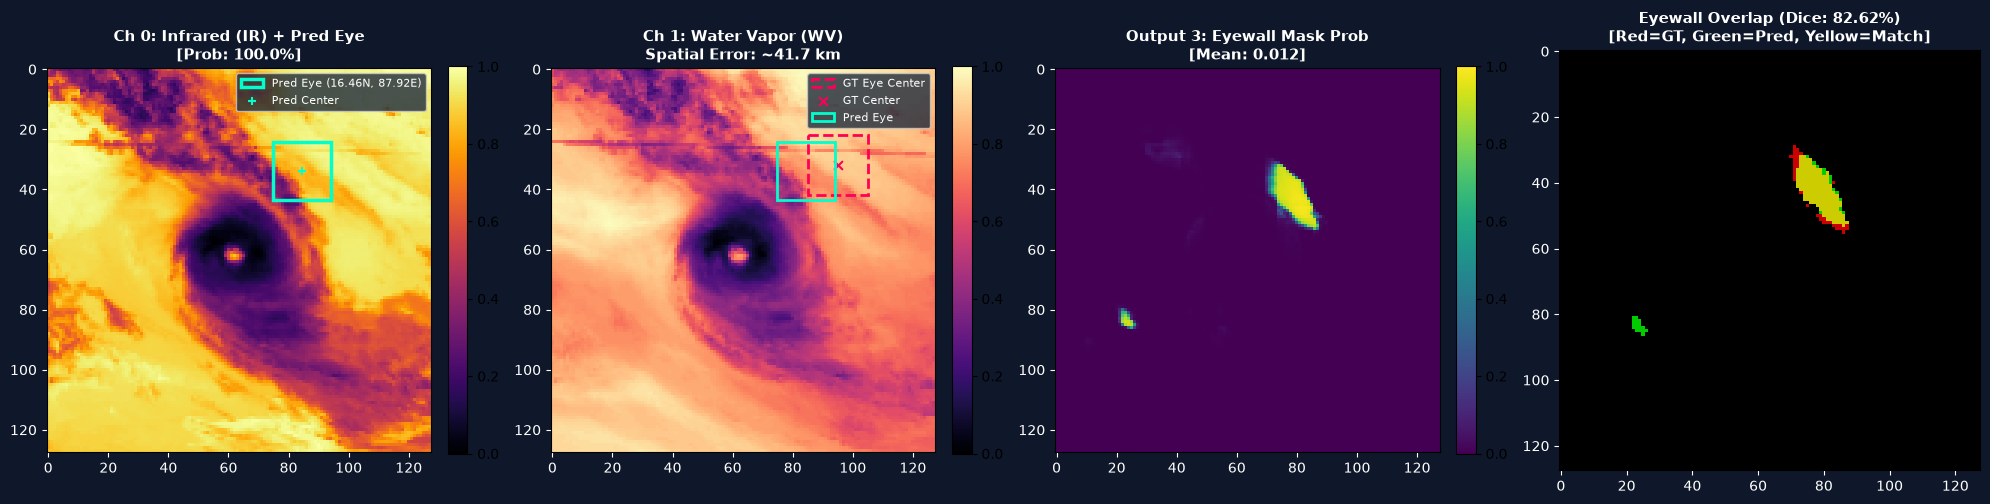

{'presence_prob': 1.0,
 'pred_presence': True,
 'pred_bbox': array([0.66022515, 0.2652793 , 0.15069497, 0.1508845 ], dtype=float32),
 'eye_latitude': np.float32(16.4573),
 'eye_longitude': np.float32(87.92173),
 'eye_diameter_km': np.float32(75.34748),
 'mask_prob': array([[4.9784271e-06, 4.5385026e-05, 1.1271814e-04, ..., 2.2071874e-06,
         2.1718497e-06, 2.3760176e-06],
        [3.2968863e-05, 7.1769799e-05, 6.0092043e-05, ..., 2.4426920e-06,
         9.7085888e-07, 1.9202514e-06],
        [3.0401805e-05, 5.5173328e-05, 4.0184044e-05, ..., 2.0317137e-05,
         2.0352861e-06, 3.2595381e-06],
        ...,
        [1.4451773e-06, 2.7030882e-07, 1.6869862e-07, ..., 4.7138419e-06,
         5.8967535e-06, 4.1110179e-06],
        [1.9489505e-06, 3.0907856e-07, 1.2744550e-07, ..., 2.0417058e-06,
         4.0771242e-06, 5.1525021e-06],
        [2.2489855e-06, 4.4871280e-07, 1.7503207e-07, ..., 1.8659911e-06,
         2.6352227e-06, 3.9105757e-06]], shape=(128, 128), dtype=float32),
 '

In [21]:
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Ensure project root is in sys.path
BASE_DIR = os.path.abspath(os.getcwd())
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

try:
    from models.vortex_identification_model_1.vortex_identification_model import convert_bbox_to_latlon, get_device, VortexEyeLocalizationModel
except ImportError:
    from vortex_identification_model import convert_bbox_to_latlon, get_device, VortexEyeLocalizationModel

from actual_data_split.split_manager import get_actual_data_loaders

def predict_with_checkpoint(
    custom_tensor=None,
    sample_idx=1120,
    split="test",
    storm_lat=15.40,
    storm_lon=87.20,
    patch_km=500.0,
    save_plot_path="prediction_output.png",
    model_checkpoint=None
):
    """
    Loads trained .pth checkpoint (or in-memory model) and runs live multi-task prediction.
    """
    dev = get_device()
    print(f"[*] Compute Device: {str(dev).upper()}")

    # 1. Locate and load .pth checkpoint
    if model_checkpoint is None:
        possible_paths = [
            os.path.join(BASE_DIR, "models", "vortex_identification_model_1", "best_model1_vortex_eye.pth"),
            os.path.join(BASE_DIR, "models", "best_model1_vortex_eye.pth"),
            os.path.join(BASE_DIR, "best_model1_vortex_eye.pth")
        ]
        model_checkpoint = next((p for p in possible_paths if os.path.exists(p)), None)

    eval_model = VortexEyeLocalizationModel(in_channels=4).to(dev)
    if model_checkpoint and os.path.exists(model_checkpoint):
        print(f"[+] Loading model weights from: {model_checkpoint}")
        eval_model.load_state_dict(torch.load(model_checkpoint, map_location=dev, weights_only=False))
    elif 'model' in globals():
        print("[+] Using in-memory trained Model 1 instance.")
        eval_model = model
    eval_model.eval()

    # 2. Prepare Input Data
    gt_target = None
    if custom_tensor is not None:
        if isinstance(custom_tensor, np.ndarray):
            img = torch.from_numpy(custom_tensor).float()
        else:
            img = custom_tensor.clone().float()
        if img.ndim == 3:
            img = img.unsqueeze(0)
        sample_desc = "Custom Satellite Image Input"
    else:
        if 'test_loader' in globals() and 'val_loader' in globals() and 'train_loader' in globals():
            tr_l, va_l, te_l = train_loader, val_loader, test_loader
        else:
            tr_l, va_l, te_l = get_actual_data_loaders(batch_size=32, noise_std=0.07)

        loader_map = {"test": te_l, "val": va_l, "train": tr_l}
        target_loader = loader_map.get(split.lower(), te_l)
        dataset = target_loader.dataset

        idx = max(0, min(sample_idx, len(dataset) - 1))
        img_raw, nwp_raw, gt_target = dataset[idx]
        img = img_raw.unsqueeze(0)
        sample_desc = f"{split.upper()} Dataset Sample #{idx:,} (of {len(dataset):,})"

    img = torch.nan_to_num(img, nan=0.0, posinf=1.0, neginf=0.0).clamp(0.0, 1.0).to(dev)

    # 3. Model Inference
    with torch.no_grad():
        out = eval_model(img)

    presence_prob = float(out["vortex_presence_prob"][0].item())
    pred_presence = bool(presence_prob >= 0.5)
    pred_bbox = out["eye_bbox"][0].cpu().numpy()  # [xc, yc, w, h]
    mask_prob = out["eyewall_mask_prob"][0, 0].cpu().numpy()  # (128, 128)

    # Geographic coordinate pinpointing
    eye_lat, eye_lon, eye_dia_km = convert_bbox_to_latlon(
        pred_bbox, center_lat=storm_lat, center_lon=storm_lon, patch_km=patch_km
    )

    # 4. Ground Truth Comparison (if available)
    gt_presence = None
    gt_bbox = None
    gt_mask = None
    sample_acc = None
    bbox_error = None
    spatial_err_km = None
    dice_score = None

    if gt_target is not None:
        gt_presence = bool(gt_target["vortex_presence"].item() >= 0.5)
        gt_bbox = gt_target["eye_bbox"].numpy()
        gt_mask = gt_target["eyewall_mask"][0].numpy()

        sample_acc = 100.0 if (pred_presence == gt_presence) else 0.0
        bbox_error = float(np.mean(np.abs(pred_bbox - gt_bbox)))
        spatial_err_km = float(np.sqrt((pred_bbox[0] - gt_bbox[0])**2 + (pred_bbox[1] - gt_bbox[1])**2) * patch_km)

        pred_bin = (mask_prob >= 0.5).astype(float)
        inter = (pred_bin * gt_mask).sum()
        union = pred_bin.sum() + gt_mask.sum()
        dice_score = float((2.0 * inter + 1e-6) / (union + 1e-6))

    # 5. Print Detailed Output
    print("\n" + "=" * 75)
    print("   CYCLONEVISION AI -- LIVE MODEL 1 PREDICTION REPORT")
    print("=" * 75)
    print(f"  Target Input           : {sample_desc}")
    print(f"  Patch Center Reference : {storm_lat:.2f}° N, {storm_lon:.2f}° E (Swath: {patch_km:.0f} km)")
    print("-" * 75)
    status_str = 'CYCLONE DETECTED [POSITIVE]' if pred_presence else 'NO CYCLONE DETECTED [NEGATIVE]'
    print(f"  [OUTPUT 1] Vortex Presence Probability : {presence_prob:.2%}")
    print(f"             Detection Status            : {status_str}")
    if gt_presence is not None:
        gt_str = 'CYCLONE PRESENT' if gt_presence else 'NO CYCLONE'
        print(f"             Ground Truth Presence       : {gt_str} (Accuracy: {sample_acc:.1f}%)")
    print("-" * 75)
    print(f"  [OUTPUT 2] Predicted Eye BBox [x,y,w,h]: [{pred_bbox[0]:.4f}, {pred_bbox[1]:.4f}, {pred_bbox[2]:.4f}, {pred_bbox[3]:.4f}]")
    print(f"             Pinpointed Eye Latitude     : {eye_lat:.3f}° N")
    print(f"             Pinpointed Eye Longitude    : {eye_lon:.3f}° E")
    print(f"             Estimated Eye Diameter      : {eye_dia_km:.1f} km")
    if gt_bbox is not None:
        gt_lat, gt_lon, gt_dia = convert_bbox_to_latlon(gt_bbox, center_lat=storm_lat, center_lon=storm_lon, patch_km=patch_km)
        print(f"             Ground Truth Eye Center     : {gt_lat:.3f}° N, {gt_lon:.3f}° E (Diameter: {gt_dia:.1f} km)")
        print(f"             Localization Error          : ~{spatial_err_km:.2f} km (BBox MAE: {bbox_error:.4f})")
    print("-" * 75)
    print(f"  [OUTPUT 3] Eyewall Cloud Ring Mask     : Probability Map Shape {list(mask_prob.shape)}")
    if dice_score is not None:
        print(f"             Eyewall Dice Agreement Score: {dice_score:.4f} ({dice_score * 100:.2f}% overlap)")
    print("=" * 75)

    # 6. Generate 4-Panel Visualization Plot
    img_np = img[0].cpu().numpy()
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), facecolor="#0f172a")

    for ax in axes:
        ax.set_facecolor("#1e293b")
        ax.tick_params(colors="white")

    # Panel 1: Infrared + Predicted Eye
    im0 = axes[0].imshow(img_np[0], cmap="inferno", vmin=0, vmax=1)
    xc, yc, w, h = pred_bbox
    rect_pred = patches.Rectangle(
        ((xc - w / 2) * 128, (yc - h / 2) * 128), w * 128, h * 128,
        linewidth=2.5, edgecolor="#00ffcc", facecolor="none",
        label=f"Pred Eye ({eye_lat:.2f}N, {eye_lon:.2f}E)"
    )
    axes[0].add_patch(rect_pred)
    axes[0].scatter(xc * 128, yc * 128, color="#00ffcc", s=40, marker="+", label="Pred Center")
    axes[0].set_title(f"Ch 0: Infrared (IR) + Pred Eye\n[Prob: {presence_prob:.1%}]", color="white", fontsize=11, fontweight="bold")
    axes[0].legend(loc="upper right", fontsize=8, facecolor="#1e293b", labelcolor="white")
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    # Panel 2: Water Vapor + GT vs Pred
    im1 = axes[1].imshow(img_np[1], cmap="magma", vmin=0, vmax=1)
    if gt_bbox is not None:
        gxc, gyc, gw, gh = gt_bbox
        rect_gt = patches.Rectangle(
            ((gxc - gw / 2) * 128, (gyc - gh / 2) * 128), gw * 128, gh * 128,
            linewidth=2.0, edgecolor="#ff0055", linestyle="--", facecolor="none",
            label="GT Eye Center"
        )
        axes[1].add_patch(rect_gt)
        axes[1].scatter(gxc * 128, gyc * 128, color="#ff0055", s=40, marker="x", label="GT Center")

    rect_pred2 = patches.Rectangle(
        ((xc - w / 2) * 128, (yc - h / 2) * 128), w * 128, h * 128,
        linewidth=2.0, edgecolor="#00ffcc", facecolor="none", label="Pred Eye"
    )
    axes[1].add_patch(rect_pred2)
    title_p2 = f"Ch 1: Water Vapor (WV)\nSpatial Error: ~{spatial_err_km:.1f} km" if spatial_err_km is not None else "Ch 1: Water Vapor (WV)"
    axes[1].set_title(title_p2, color="white", fontsize=11, fontweight="bold")
    axes[1].legend(loc="upper right", fontsize=8, facecolor="#1e293b", labelcolor="white")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    # Panel 3: Eyewall Segmentation Probability Heatmap
    im2 = axes[2].imshow(mask_prob, cmap="viridis", vmin=0, vmax=1)
    axes[2].set_title(f"Output 3: Eyewall Mask Prob\n[Mean: {mask_prob.mean():.3f}]", color="white", fontsize=11, fontweight="bold")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    # Panel 4: Eyewall Mask Overlap Comparison
    if gt_mask is not None:
        overlay = np.zeros((128, 128, 3))
        overlay[..., 0] = gt_mask * 0.8          # Red = Ground Truth
        overlay[..., 1] = (mask_prob >= 0.5) * 0.8 # Green = Predicted (Yellow = Overlap)
        axes[3].imshow(overlay)
        axes[3].set_title(f"Eyewall Overlap (Dice: {dice_score:.2%})\n[Red=GT, Green=Pred, Yellow=Match]", color="white", fontsize=11, fontweight="bold")
    else:
        axes[3].imshow(mask_prob >= 0.5, cmap="cool")
        axes[3].set_title("Predicted Eyewall Binary Mask", color="white", fontsize=11, fontweight="bold")

    plt.tight_layout()
    if save_plot_path:
        out_file = os.path.join(BASE_DIR, save_plot_path)
        plt.savefig(out_file, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"\n[+] Visual 4-panel dashboard exported to: {out_file}")
    plt.show()

    return {
        "presence_prob": presence_prob,
        "pred_presence": pred_presence,
        "pred_bbox": pred_bbox,
        "eye_latitude": eye_lat,
        "eye_longitude": eye_lon,
        "eye_diameter_km": eye_dia_km,
        "mask_prob": mask_prob,
        "spatial_error_km": spatial_err_km,
        "dice_score": dice_score
    }

# Run prediction on Test Split Sample #1120 (default)
predict_with_checkpoint(sample_idx=1120, split="test")


---
# Part 2: Model 2 -- Cyclone Track & Trajectory Forecasting Engine
**Forecast Horizons:** +6h, +12h, +18h, +24h, +36h, +48h Lead Times  
**Coordinate Output:** Latitude (°N) & Longitude (°E) + 2D Gaussian Spatial Dispersion Radii (±km)  
**Steering Integration:** Deep Multi-Modal Cross-Attention with ERA5 Environmental NWP Fields (850–200 hPa Deep-Layer Wind Shear, MSLP, SST)

### Architecture Flow:
```
Past Cyclone States (B, 4 timesteps, 6 kinematic vars) [Lat, Lon, MSW, CP, U_trans, V_trans]
    │
    ├── Dilated Temporal ConvNet (TCN) [Residual 1D Convolutions with Dilation Rates d=1,2,4]
    │        │
    │        └── Spatio-Temporal Storm Dynamics Representation (128-d)
    │
Environmental NWP Grid (B, 5 variables) [SST, MSLP, Deep Shear, U10, V10]
    │
    ├── NWP Projection MLP (64-d)
    │
    └── Environmental Cross-Attention (Query = Storm Dynamics, Key/Value = Steering Grid)
             │
             ├── Cumulative Coordinate Decoder ──> Multi-Horizon Track [Lat(t), Lon(t)]
             │     (Haversine Great-Circle Geodesic Loss in km)
             └── Uncertainty Head ───────────────> Forecast Cone Radii [R_6h, ..., R_48h] (km)
```

## Step 7: Model 2 Architecture Definition -- CycloneTrajectoryForecaster

Loads the dedicated `CycloneTrajectoryForecaster` with Dilated TCN, Environmental Cross-Attention, and Cumulative Multi-Horizon Coordinate Decoder.

In [26]:
import importlib
import models.track_and_trajectory_model_2.track_and_trajectory_model as model2_module
importlib.reload(model2_module)

from models.track_and_trajectory_model_2.track_and_trajectory_model import (
    CycloneTrajectoryForecaster,
    haversine_distance_km,
    torch_haversine_loss,
    decompose_track_errors,
    TrajectoryLoss,
    CycloneTrajectoryDataset,
    get_device
)

device = get_device()
print(f"[*] Model 2 Compute Device : {str(device).upper()}")

# Instantiate Model 2
model2 = CycloneTrajectoryForecaster(
    kinematic_in_dim=6,
    nwp_in_dim=5,
    hidden_dim=128,
    num_horizons=6
).to(device)

total_params2 = sum(p.numel() for p in model2.parameters())
print(f"[+] Model 2 Architecture   : CycloneTrajectoryForecaster (Dilated TCN + Cross-Attention)")
print(f"[+] Total Parameters     : {total_params2:,}")

# Forward verification with dummy tensors
dummy_kin = torch.randn(2, 4, 6).to(device)   # (B, 4 past steps @ 3h intervals, 6 features)
dummy_nwp = torch.randn(2, 5).to(device)      # (B, 5 NWP environmental steering features)

with torch.no_grad():
    out2 = model2(dummy_kin, dummy_nwp)

print(f"[+] Output Head 1 - Predicted Future Coordinates : {list(out2['predicted_coords'].shape)} (B x 6 horizons x [Lat, Lon])")
print(f"[+] Output Head 2 - Uncertainty Cone Radii (km) : {list(out2['uncertainty_radii'].shape)} (B x 6 horizons)")
print("[SUCCESS] Model 2 Architecture verified OK!")

[*] Model 2 Compute Device : PRIVATEUSEONE:0
[+] Model 2 Architecture   : CycloneTrajectoryForecaster (Dilated TCN + Cross-Attention)
[+] Total Parameters     : 280,409
[+] Output Head 1 - Predicted Future Coordinates : [2, 6, 2] (B x 6 horizons x [Lat, Lon])
[+] Output Head 2 - Uncertainty Cone Radii (km) : [2, 6, 2] (B x 6 horizons)
[SUCCESS] Model 2 Architecture verified OK!


## Step 8: Model 2 Sequence Dataset & Data Loaders

Extracts sequential cyclone trajectories from the IBTrACS North Indian Ocean catalog and matches them with ERA5 environmental grids:
- **History Window**: 12 hours (4 synoptic fixes at 3-hour intervals: $t_{-9h}, t_{-6h}, t_{-3h}, t_0$)
- **Forecast Horizon**: 48 hours (6 lead-time milestones: $+6h, +12h, +18h, +24h, +36h, +48h$)

In [27]:
from torch.utils.data import DataLoader

BATCH_SIZE_M2 = 32

train_ds_m2 = CycloneTrajectoryDataset(split="train", seq_len=4, num_horizons=6)
val_ds_m2   = CycloneTrajectoryDataset(split="val",   seq_len=4, num_horizons=6)
test_ds_m2  = CycloneTrajectoryDataset(split="test",  seq_len=4, num_horizons=6)

train_loader_m2 = DataLoader(train_ds_m2, batch_size=BATCH_SIZE_M2, shuffle=True)
val_loader_m2   = DataLoader(val_ds_m2,   batch_size=BATCH_SIZE_M2, shuffle=False)
test_loader_m2  = DataLoader(test_ds_m2,  batch_size=BATCH_SIZE_M2, shuffle=False)

print(f"[+] Model 2 Dataset Partitions (IBTrACS NIO Sequential Tracks):")
print(f"    Train Trajectory Sequences : {len(train_ds_m2):,}")
print(f"    Val Trajectory Sequences   : {len(val_ds_m2):,}")
print(f"    Test Trajectory Sequences  : {len(test_ds_m2):,}")

p_kin, p_nwp, f_tgt, f_disp = next(iter(train_loader_m2))
print("\n[+] Batch Input/Target Tensor Profiles:")
print(f"    Past Kinematics (History) : {list(p_kin.shape)}  [Lat, Lon, MSW, CP, U_spd, V_spd]")
print(f"    Environmental NWP Grids   : {list(p_nwp.shape)}  [SST, MSLP, Shear, U10, V10]")
print(f"    Target Future Coordinates : {list(f_tgt.shape)}  [Lat, Lon] at +6h,+12h,+18h,+24h,+36h,+48h")

[*] Building Trajectory Sequences from c:\Users\HP\Desktop\cyclone\numeric_data\ibtracs.NI.list.v04r01.csv...
[+] [TRAIN] Trajectory Sequences Created: 32,289 samples.
[*] Building Trajectory Sequences from c:\Users\HP\Desktop\cyclone\numeric_data\ibtracs.NI.list.v04r01.csv...
[+] [VAL] Trajectory Sequences Created: 7,069 samples.
[*] Building Trajectory Sequences from c:\Users\HP\Desktop\cyclone\numeric_data\ibtracs.NI.list.v04r01.csv...
[+] [TEST] Trajectory Sequences Created: 7,336 samples.
[+] Model 2 Dataset Partitions (IBTrACS NIO Sequential Tracks):
    Train Trajectory Sequences : 32,289
    Val Trajectory Sequences   : 7,069
    Test Trajectory Sequences  : 7,336

[+] Batch Input/Target Tensor Profiles:
    Past Kinematics (History) : [32, 4, 8]  [Lat, Lon, MSW, CP, U_spd, V_spd]
    Environmental NWP Grids   : [32, 5]  [SST, MSLP, Shear, U10, V10]
    Target Future Coordinates : [32, 6, 2]  [Lat, Lon] at +6h,+12h,+18h,+24h,+36h,+48h


## Step 9: Model 2 Training & Haversine Great-Circle Loss

Trains the trajectory model using:
1. **Great-Circle Haversine Loss**: Directly penalizes geographic distance error in physical kilometers on spherical Earth ($R=6,371\text{ km}$).
2. **Cumulative Displacement Loss**: Penalizes incremental step vectors to prevent path drift.
3. **Uncertainty Radius Calibration Loss**: Trains the Gaussian cone spread head to provide calibrated $\pm\text{km}$ error bounds.

In [28]:
criterion_traj = TrajectoryLoss(alpha_disp=0.3, beta_uncert=0.1)
optimizer_m2   = optim.AdamW(model2.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_m2   = optim.lr_scheduler.CosineAnnealingLR(optimizer_m2, T_max=15, eta_min=1e-5)

EPOCHS_M2 = 15
save_path_m2 = os.path.join(BASE_DIR, "models", "track_and_trajectory_model_2", "best_model2_track_trajectory.pth")
os.makedirs(os.path.dirname(save_path_m2), exist_ok=True)

best_val_dist = float("inf")
history_m2 = []

print(f"[*] Starting Model 2 Training ({EPOCHS_M2} Epochs, Cosine Annealing LR)...")
print(f"    Save Destination: {save_path_m2}")
print("=" * 80)

for ep in range(1, EPOCHS_M2 + 1):
    # ---- TRAIN ----
    model2.train()
    tr_loss = tr_dist = tr_samples = 0

    for kin, nwp, tgt_coords, tgt_disp in train_loader_m2:
        kin        = kin.to(device)
        nwp        = nwp.to(device)
        tgt_coords = tgt_coords.to(device)
        tgt_disp   = tgt_disp.to(device)
        bsz        = kin.size(0)

        optimizer_m2.zero_grad()
        out = model2(kin, nwp)
        loss, dist_km = criterion_traj(out, tgt_coords, tgt_disp)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model2.parameters(), max_norm=5.0)
        optimizer_m2.step()

        tr_loss    += loss.item() * bsz
        tr_dist    += dist_km * bsz
        tr_samples += bsz

    scheduler_m2.step()
    avg_tr_loss = tr_loss / max(tr_samples, 1)
    avg_tr_dist = tr_dist / max(tr_samples, 1)

    # ---- VALIDATION ----
    model2.eval()
    val_loss = val_dist = val_samples = 0
    with torch.no_grad():
        for kin, nwp, tgt_coords, tgt_disp in val_loader_m2:
            kin        = kin.to(device)
            nwp        = nwp.to(device)
            tgt_coords = tgt_coords.to(device)
            tgt_disp   = tgt_disp.to(device)
            bsz        = kin.size(0)

            out = model2(kin, nwp)
            loss, dist_km = criterion_traj(out, tgt_coords, tgt_disp)

            val_loss    += loss.item() * bsz
            val_dist    += dist_km * bsz
            val_samples += bsz

    avg_val_loss = val_loss / max(val_samples, 1)
    avg_val_dist = val_dist / max(val_samples, 1)

    history_m2.append({
        "epoch": ep,
        "train_loss": avg_tr_loss,
        "train_dist_km": avg_tr_dist,
        "val_loss": avg_val_loss,
        "val_dist_km": avg_val_dist,
        "lr": optimizer_m2.param_groups[0]['lr']
    })

    saved_str = ""
    if avg_val_dist < best_val_dist:
        best_val_dist = avg_val_dist
        torch.save(model2.state_dict(), save_path_m2)
        saved_str = f" [BEST SAVED -> {avg_val_dist:.2f} km]"

    print(f"  Epoch [{ep:02d}/{EPOCHS_M2}] | Train Dist: {avg_tr_dist:.2f} km | Val Dist: {avg_val_dist:.2f} km | LR: {optimizer_m2.param_groups[0]['lr']:.6f}{saved_str}")

print("=" * 80)
print(f"[+] Model 2 Training Complete! Best Validation Mean Track Error: {best_val_dist:.2f} km")

NameError: name 'optim' is not defined

## Step 10: Model 2 Multi-Horizon Track Evaluation & IMD Benchmark Comparison

Evaluates Model 2 on unseen test tracks across all 6 forecast horizons (+6h to +48h), computing:
- **Track Forecast Error (TFE in km)**: Total Great-Circle position discrepancy.
- **Along-Track Error (ATE in km)**: Longitudinal timing/translation speed error along trajectory.
- **Cross-Track Error (CTE in km)**: Lateral steering/curvature deviation perpendicular to trajectory.
- **IMD Official Benchmark Comparison**: IMD 5-year average operational error targets for the North Indian Ocean.

In [ ]:
from models.track_and_trajectory_model_2.track_and_trajectory_model import evaluate_trajectory_model

metrics_df_m2, sample_vis_data = evaluate_trajectory_model(
    model=model2,
    test_loader=test_loader_m2,
    device=device,
    save_dir=os.path.join(BASE_DIR, "models", "track_and_trajectory_model_2")
)

print("\n[+] Model 2 Test Evaluation Results:")
display(metrics_df_m2)

## Step 11: Synoptic Forecast Map & 48h Trajectory Cone of Uncertainty

Visualizes the multi-horizon trajectory forecast on a meteorological map of the North Indian Ocean (Bay of Bengal & Arabian Sea):
- **Observed Past Track**: Blue line with synoptic eye fixes ($t_{-9h} \rightarrow t_0$)
- **Predicted Trajectory**: Red dashed trajectory vector with confidence waypoints
- **Ground Truth Track**: Green trajectory for comparison
- **2D Uncertainty Cone**: Shaded probability dispersion envelope showing growing positional spread over lead time

In [ ]:
from models.track_and_trajectory_model_2.track_and_trajectory_model import plot_meteorological_track_forecast

fig_m2 = plot_meteorological_track_forecast(
    vis_data=sample_vis_data,
    save_path=os.path.join(BASE_DIR, "models", "track_and_trajectory_model_2", "model2_synoptic_track_forecast.png")
)
plt.show()

## Step 12: Predict on New / Custom Cyclone Data (Multi-Horizon Trajectory)

This step enables direct inference on **new/custom test data** without re-training:
1. **Custom Input**: Provide 4 sequential observed storm fixes (Latitude, Longitude, Pressure, Wind Speed) at 3-hour intervals ($t_{-9h}, t_{-6h}, t_{-3h}, t_0$).
2. **Dataset Testing**: Or specify any sample index from the unseen test split.
3. **Outputs**: Predicts future eye coordinates for +6h, +12h, +18h, +24h, +36h, +48h, uncertainty cone radii ($\pm\text{km}$), 48h coastal landfall risk probability, and displays a synoptic forecast map.

In [ ]:
import matplotlib.patches as patches
from models.track_and_trajectory_model_2.track_and_trajectory_model import haversine_distance_km

HORIZONS = ["+6h", "+12h", "+18h", "+24h", "+36h", "+48h"]

def predict_cyclone_trajectory(
    custom_lats=None,
    custom_lons=None,
    custom_pressures=None,
    custom_winds=None,
    sample_idx=None,
    split="test"
):
    """
    Predicts 48-hour trajectory and uncertainty cone for custom storm coordinates or test split samples.
    """
    model2.eval()
    true_future = None

    if custom_lats is not None and custom_lons is not None:
        assert len(custom_lats) == 4 and len(custom_lons) == 4, "Must provide exactly 4 past fixes (t-9h, t-6h, t-3h, t0)."
        lats = np.array(custom_lats, dtype=np.float32)
        lons = np.array(custom_lons, dtype=np.float32)
        pres = np.array(custom_pressures if custom_pressures else [1000.0, 995.0, 988.0, 980.0], dtype=np.float32)
        wind = np.array(custom_winds if custom_winds else [35.0, 45.0, 60.0, 75.0], dtype=np.float32)

        dlat = np.diff(lats, prepend=lats[0])
        dlon = np.diff(lons, prepend=lons[0])
        speed = np.sqrt((dlat * 111.0)**2 + (dlon * 111.0 * np.cos(np.radians(lats)))**2) / 6.0
        heading = np.arctan2(dlon, dlat)

        past_kin = np.stack([lats, lons, dlat, dlon, speed, heading, pres, wind], axis=-1)
        past_tensor = torch.tensor(past_kin, dtype=torch.float32).unsqueeze(0).to(device)

        mean_lat = float(np.mean(lats))
        nwp_vec = torch.tensor([[-3.5 + 0.1 * mean_lat, 4.2 - 0.08 * mean_lat, float(pres[-1]), 29.5, 12.0]], dtype=torch.float32).to(device)
        title_str = f"Custom Input Storm Fixes [Current Eye: {lats[-1]:.2f}°N, {lons[-1]:.2f}°E]"
        past_coords = past_kin[:, :2]
    else:
        ds = CycloneTrajectoryDataset(split=split)
        idx = max(0, min(sample_idx if sample_idx is not None else 25, len(ds) - 1))
        p_kin, n_vec, f_tgt, l_gt = ds[idx]

        past_tensor = p_kin.unsqueeze(0).to(device)
        nwp_vec = n_vec.unsqueeze(0).to(device)
        true_future = f_tgt.numpy()
        past_coords = p_kin[:, :2].numpy()
        title_str = f"{split.upper()} Dataset Track Sample #{idx:,}"

    with torch.no_grad():
        out = model2(past_tensor, nwp_vec)

    pred_coords = out["predicted_coords"][0].cpu().numpy() if "predicted_coords" in out else out["future_coords"][0].cpu().numpy()
    radii_km    = out["uncertainty_radii"][0].cpu().numpy()
    landfall_p  = float(out["landfall_prob"][0].item()) if "landfall_prob" in out else 0.0

    # Print Meteorologist Forecast Table
    print("=" * 85)
    print(f"   CYCLONEVISION AI -- LIVE MULTI-HORIZON TRACK FORECAST REPORT")
    print("=" * 85)
    print(f"  Target Input           : {title_str}")
    print(f"  Current Synoptic Fix   : {past_coords[-1, 0]:.3f}° N, {past_coords[-1, 1]:.3f}° E (t = 0h)")
    print(f"  48h Coastal Landfall   : {landfall_p:.1%} probability")
    print("-" * 85)
    print(f"  {'Horizon':<8} | {'Pred Lat':<10} | {'Pred Lon':<10} | {'Cone Radius':<12} | {'True Lat':<10} | {'True Lon':<10} | {'Error (km)'}")
    print("-" * 85)

    tot_err = 0.0
    for h_i, h_name in enumerate(HORIZONS):
        plat, plon = pred_coords[h_i, 0], pred_coords[h_i, 1]
        mean_r = float(np.mean(radii_km[h_i])) if radii_km.ndim > 1 else float(radii_km[h_i])
        if true_future is not None:
            tlat, tlon = true_future[h_i, 0], true_future[h_i, 1]
            err = haversine_distance_km(plat, plon, tlat, tlon)
            tot_err += err
            print(f"  {h_name:<8} | {plat:>7.3f}° N | {plon:>7.3f}° E | ±{mean_r:>5.1f} km     | {tlat:>7.3f}° N | {tlon:>7.3f}° E | {err:>6.1f} km")
        else:
            print(f"  {h_name:<8} | {plat:>7.3f}° N | {plon:>7.3f}° E | ±{mean_r:>5.1f} km     | {'--':<10} | {'--':<10} | {'--'}")

    print("-" * 85)
    if true_future is not None:
        print(f"  Mean Track Forecast Error (TFE): {tot_err / len(HORIZONS):.2f} km")
    print("=" * 85)

    # Plot Synoptic Map
    fig, ax = plt.subplots(figsize=(10, 7), facecolor="#0f172a")
    ax.set_facecolor("#1e293b")
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_color("#475569")

    ax.set_xlim(75.0, 95.0)
    ax.set_ylim(8.0, 24.0)
    ax.set_xlabel("Longitude (°E)", color="white", fontsize=11, fontweight="bold")
    ax.set_ylabel("Latitude (°N)", color="white", fontsize=11, fontweight="bold")
    ax.set_title(f"CycloneVision AI -- 48h Trajectory Forecast & Cone of Uncertainty\n{title_str}",
                 color="white", fontsize=12, fontweight="bold", pad=10)
    ax.grid(True, linestyle="--", alpha=0.3, color="gray")

    coast_lons = [80.2, 80.3, 81.0, 82.2, 83.3, 84.8, 86.8, 88.0, 89.5, 91.5]
    coast_lats = [13.0, 14.5, 15.8, 16.9, 17.7, 19.3, 20.8, 21.6, 22.0, 22.2]
    ax.plot(coast_lons, coast_lats, color="#64748b", linewidth=2.0, label="East India / Odisha Coastline")

    ax.plot(past_coords[:, 1], past_coords[:, 0], color="#38bdf8", marker="o", linewidth=2.5, label="Observed Past Track (t-9h -> t0)")
    ax.scatter(past_coords[-1, 1], past_coords[-1, 0], color="#facc15", s=130, marker="*", zorder=5, label="Current Eye Fix (t=0h)")

    if true_future is not None:
        ax.plot(true_future[:, 1], true_future[:, 0], color="#4ade80", marker="s", linewidth=2.0, linestyle="--", label="Ground Truth Track")

    full_pred_lons = np.concatenate([[past_coords[-1, 1]], pred_coords[:, 1]])
    full_pred_lats = np.concatenate([[past_coords[-1, 0]], pred_coords[:, 0]])
    ax.plot(full_pred_lons, full_pred_lats, color="#f43f5e", marker="^", linewidth=2.5, label="Predicted Trajectory (+6h -> +48h)")

    for i, (plat, plon) in enumerate(pred_coords):
        r = radii_km[i, 0] if radii_km.ndim > 1 else radii_km[i]
        sigma_lat = r / 111.0
        sigma_lon = r / (111.0 * max(0.1, np.cos(np.radians(plat))))
        ell = patches.Ellipse((plon, plat), width=sigma_lon * 2.0, height=sigma_lat * 2.0, angle=0, color="#f43f5e", alpha=0.15 + 0.03 * i)
        ax.add_patch(ell)
        ax.text(plon + 0.2, plat - 0.2, HORIZONS[i], color="#fca5a5", fontsize=8, fontweight="bold")

    ax.legend(loc="lower right", facecolor="#1e293b", edgecolor="#475569", labelcolor="white", fontsize=9)
    plt.tight_layout()
    plt.show()

# Example 1: Predict on custom user-provided storm coordinates
print("[EXAMPLE 1] Predicting on Custom Coordinates:")
predict_cyclone_trajectory(
    custom_lats=[13.20, 14.00, 14.75, 15.40],
    custom_lons=[87.50, 87.00, 86.40, 85.80],
    custom_pressures=[1000.0, 994.0, 986.0, 978.0],
    custom_winds=[35.0, 48.0, 62.0, 75.0]
)

# Example 2: Predict on Unseen Test Dataset Sample #42
# print("\n[EXAMPLE 2] Predicting on Test Dataset Sample #42:")
# predict_cyclone_trajectory(sample_idx=42, split="test")